In [ ]:
from pacman_rl import PPOConfig, train_ppo, save_run, load_run, ppo_policy, watch, evaluate, get_device
from pacman_rl.plotting import plot_training

device = get_device()
print(f"Using device: {device}")
cfg = PPOConfig(
    total_steps=50_000, 
    n_envs=64, 
    seed=1,
    epochs=4,
    n_mini_batches=4,
    lr=2.5e-4,
    gamma=0.99,
    lam=0.95,
    clip_eps=0.1,
    ) 
# Nạp lại cấu hình PPO từ tệp tin đã train
ppo = load_run(".","ms_pacman_ppo", "ppo", device=device)

Using device: cuda


In [2]:
new_model = train_ppo(
    PPOConfig(
        total_steps=50_000, seed=1
    ),
    model=ppo.model, device=device,
    save_path="ms_pacman_ppo_23_10.pt"
)
# save_run(new_model, ".", "ms_pacman_ppo_test")

PPO: 24 updates x 2048 mẫu = 49,152 bước, 16 env song song
Update 24/24 | step 49,152 | avg score(20) 904 | viên NL 70 | ma 56 | entropy 1.062 | KL -0.0001 | clipfrac 0.000 | 2619 steps/s


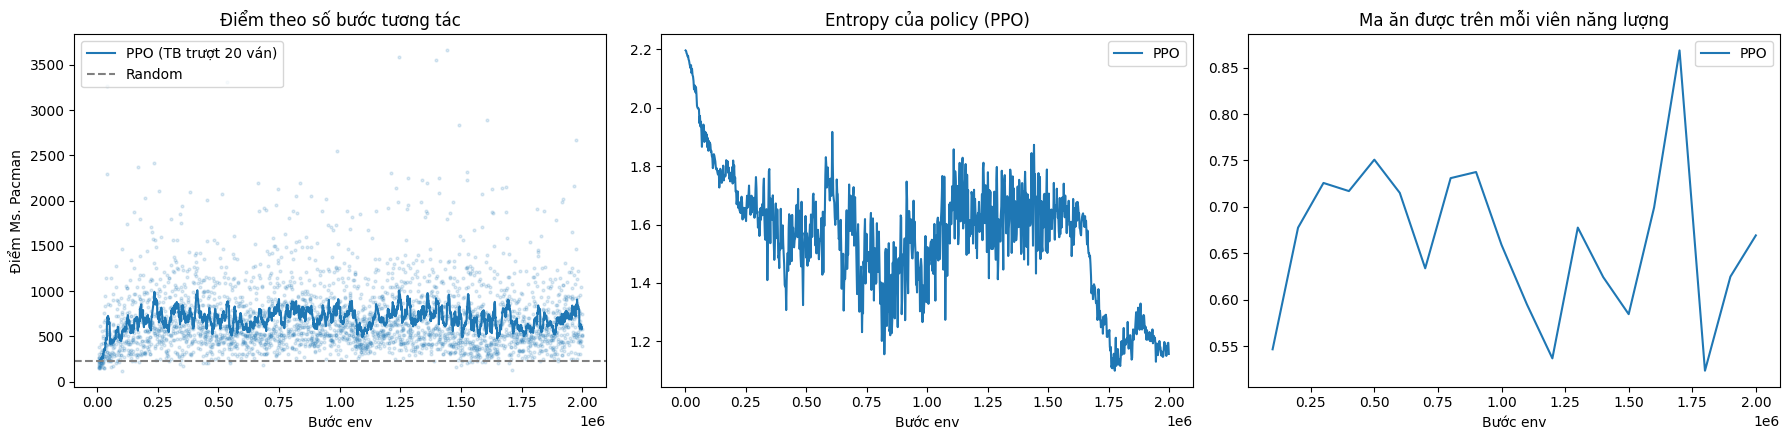

<Axes: title={'center': 'q_mean'}, xlabel='Bước env'>

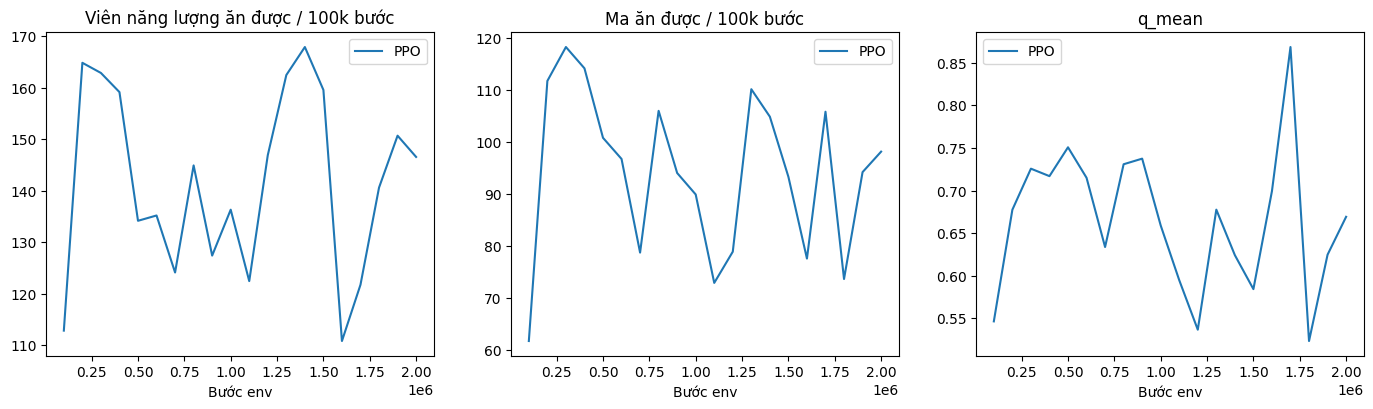

In [6]:
from pacman_rl import random_baseline
from pacman_rl.plotting import plot_training, plot_scores, plot_metric, plot_events, plot_eval

runs = {"PPO": ppo}                # tên -> TrainResult; một hay nhiều run đều được
plot_training(runs, random_scores=random_baseline(5), save_path="curves.png")
plot_events(runs)                                # viên năng lượng / ma ăn được mỗi 100k bước
plot_metric(runs, "q_mean")                      # chỉ số bất kỳ trong log; run không có thì bỏ qua


Method       mean      std      max
Random        232       41      300
PPO           546      195      910


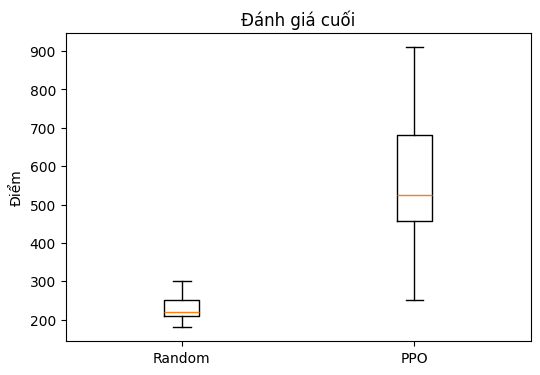

[play] ván 1: 500 điểm (800 bước)
[play] ván 2: 330 điểm (619 bước)


[500.0, 330.0]

In [3]:
from pacman_rl import evaluate, watch, ppo_policy, dqn_policy
from pacman_rl.plotting import plot_eval
from pacman_rl import random_baseline

act_ppo = ppo_policy(ppo.model, device)              # greedy=True: luôn chọn action tốt nhất

plot_eval({"Random": random_baseline(5),
           "PPO": evaluate(act_ppo, n_episodes=10),  # seed cố định 1000..1009, công bằng giữa các phương pháp
           })

watch(act_ppo, episodes=2)                           # mở cửa sổ game, cần màn hình
